# Türkiye'de Ulusal Kimlik Beyanları: Bir Meta-Analiz (2006–2025)

**Soru:** Kamuoyu araştırmalarında Türk ulusal kimliğinin dışında ya da karşısında konumlanan kimlik beyanlarının (Kürt/Zaza etnik kimliği, birincil kimlik olarak Kürt/Alevi, ulusal ad olarak "Türkiyeli") payı ne kadar, zamanla değişiyor mu ve ölçüm biçimine göre farklılaşıyor mu?

**Veri:** 5 kurumdan 18 bağımsız örneklem (Kadir Has Üniversitesi 2011–2022, KONDA 2006/2011/2018/2021, Eğitim-Bir-Sen 2010, AREA Araştırma 2025). Her satırın kaynağı `data/coding_table.csv` içinde.

**Yöntem:** Logit dönüşümlü oranlar, DerSimonian-Laird rastgele etkiler modeli, %95 güven aralığı (kaynak araştırmaların raporladığı güven düzeyi). Heterojenlik (Q, I², τ²), alt grup analizi, meta-regresyon, birini-dışarıda-bırak ve duyarlılık analizleri, Egger testi.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, numpy as np
from meta import pool, subgroup_test, meta_regression, leave_one_out, egger_test, wilson_ci
from plots import forest, funnel, khas_trend
pd.set_option('display.float_format', lambda v: f'{v:.2f}')
pd.set_option('display.width', 200)

df = pd.read_csv('../data/coding_table.csv')
alevi = pd.read_csv('../data/alevi_table.csv')
df[['study_id','institution','field_year','n','n_assumed','measure_type','outcome','pct','mode']]

,study_id,institution,field_year,n,n_assumed,measure_type,outcome,pct,mode
0,KHAS2011,Kadir Has Üniversitesi,2011,1000,0,etnik köken,Kürt+Zaza,9.20,yüz yüze
1,KHAS2012,Kadir Has Üniversitesi,2012,1000,0,etnik köken,Kürt+Zaza,6.30,yüz yüze
2,KHAS2013,Kadir Has Üniversitesi,2013,1000,0,etnik köken,Kürt+Zaza,9.30,yüz yüze
3,KHAS2014,Kadir Has Üniversitesi,2014,1000,0,etnik köken,Kürt+Zaza,10.90,yüz yüze
4,KHAS2015,Kadir Has Üniversitesi,2015,1000,0,etnik köken,Kürt+Zaza,11.50,yüz yüze
5,KHAS2016,Kadir Has Üniversitesi,2016,1000,0,etnik köken,Kürt+Zaza,11.90,yüz yüze
6,KHAS2017,Kadir Has Üniversitesi,2017,1000,0,etnik köken,Kürt+Zaza,6.20,yüz yüze
7,KHAS2018,Kadir Has Üniversitesi,2018,1000,0,etnik köken,Kürt+Zaza,10.00,yüz yüze
8,KHAS2019,Kadir Has Üniversitesi,2019,1000,0,etnik köken,Kürt+Zaza,14.10,yüz yüze
9,KHAS2020,Kadir Has Üniversitesi,2020,1000,0,etnik köken,Kürt+Zaza,11.80,yüz yüze


## 1. Genel havuzlanmış tahmin: alternatif/muhalif kimlik beyanı

In [2]:
main = pool(df, label='Tüm çalışmalar (k=18)')
pd.DataFrame([main]).drop(columns=['mu_logit','se_logit'])

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,Tüm çalışmalar (k=18),18,11.45,10.23,12.79,6.87,18.47,338.78,0.00,94.98,0.07


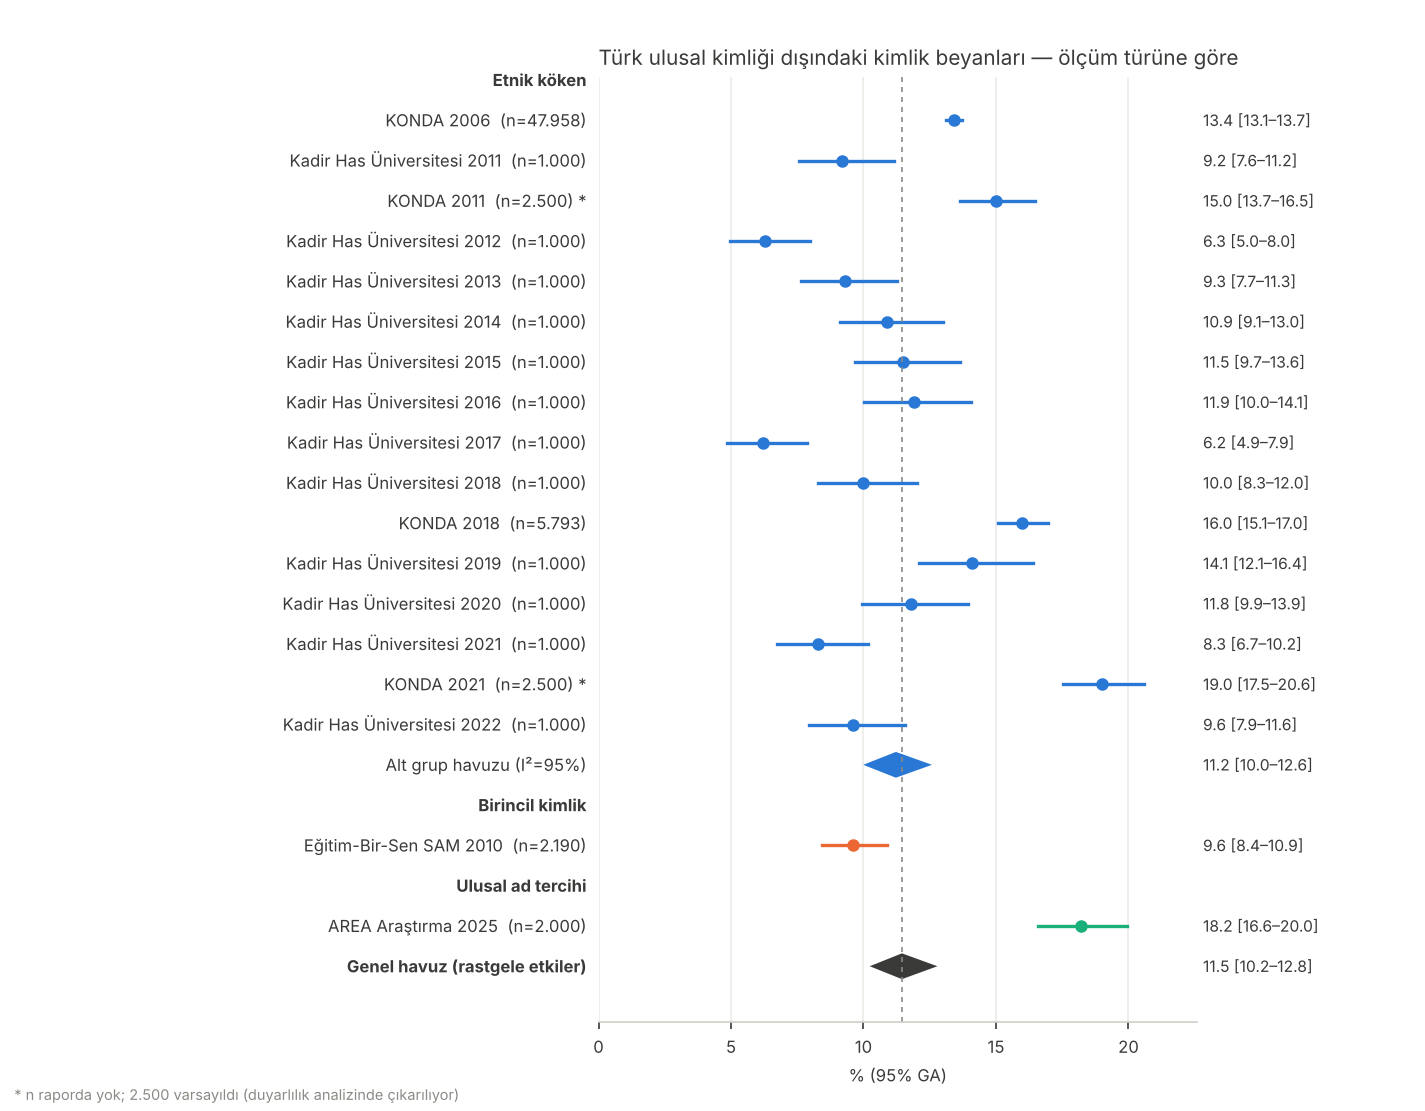

In [3]:
tot = forest(df, 'measure_type', '../outputs/figures/forest_alternatif_kimlik.png',
             'Türk ulusal kimliği dışındaki kimlik beyanları — ölçüm türüne göre')
from IPython.display import Image; Image('../outputs/figures/forest_alternatif_kimlik.png')

## 2. Alt grup analizi: ölçüm türü ve kurum

In [4]:
sg_measure, test_measure = subgroup_test(df, 'measure_type')
display(sg_measure.drop(columns=['mu_logit','se_logit'])); test_measure

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,measure_type = etnik köken,16,11.22,9.99,12.59,6.79,17.99,272.99,0.00,94.51,0.06
1,measure_type = birincil kimlik,1,9.62,8.45,10.93,NaN,NaN,0.00,NaN,0.00,0.00
2,measure_type = ulusal ad tercihi,1,18.22,16.59,19.97,NaN,NaN,0.00,NaN,0.00,0.00


{'Q_between': np.float64(75.41716826452624), 'df': 2, 'p': np.float64(0.0)}

In [5]:
sg_inst, test_inst = subgroup_test(df, 'institution')
display(sg_inst.drop(columns=['mu_logit','se_logit'])); test_inst

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,institution = Kadir Has Üniversitesi,12,9.82,8.61,11.18,5.94,15.80,64.04,0.00,82.82,0.05
1,institution = KONDA,4,15.72,13.43,18.30,7.16,31.07,87.36,0.00,96.57,0.03
2,institution = Eğitim-Bir-Sen SAM,1,9.62,8.45,10.93,NaN,NaN,0.00,NaN,0.00,0.00
3,institution = AREA Araştırma,1,18.22,16.59,19.97,NaN,NaN,0.00,NaN,0.00,0.00


{'Q_between': np.float64(92.68686656041017), 'df': 3, 'p': np.float64(0.0)}

## 3. Meta-regresyon: zaman eğilimi (yalnızca etnik köken sorusu)
Farklı soru tiplerini karıştırmamak için eğilim yalnızca etnik köken sorusunu soran 16 örneklemde test ediliyor. Yıl, 2016'ya göre merkezlendi.

In [6]:
eth = df[df.measure_type=='etnik köken'].copy()
eth['year_c'] = eth.field_year - 2016
eth['konda'] = (eth.institution=='KONDA').astype(int)
display(meta_regression(eth, ['year_c']))
meta_regression(eth, ['year_c','konda'])

,term,coef_logit,se,z,p,odds_ratio
0,intercept,-2.07,0.07,-31.12,0.00,0.13
1,year_c,0.01,0.02,0.38,0.71,1.01


,term,coef_logit,se,z,p,odds_ratio
0,intercept,-2.23,0.08,-28.39,0.00,0.11
1,year_c,0.02,0.02,1.38,0.17,1.02
2,konda,0.60,0.15,3.88,0.00,1.81


## 4. Kadir Has serisi (2011–2022)
Aynı kurumun aynı soruyla 12 yıllık tekrarlı kesitleri. 2016'da 'bilmiyorum/cevapsız' payının %20-38'den %1-3'e inmesi bir ölçüm kırılması yaratıyor; bu yüzden oran iki tabanda hesaplanıyor.

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,KHAS — tüm katılımcılar,12,9.82,8.61,11.18,5.94,15.80,64.04,0.00,82.82,0.05
1,KHAS — beyan edenler içinde,12,11.72,10.21,13.42,6.88,19.27,71.52,0.00,84.62,0.06
2,KHAS 2011–2015 (beyan edenler),5,13.61,11.76,15.70,8.25,21.63,11.70,0.02,65.81,0.02
3,KHAS 2016–2022 (beyan edenler),7,10.56,8.74,12.71,5.40,19.63,43.43,0.00,86.18,0.07


,term,coef_logit,se,z,p,odds_ratio
0,intercept,-2.00,0.08,-25.04,0.00,0.13
1,year_c,-0.03,0.02,-1.24,0.21,0.97


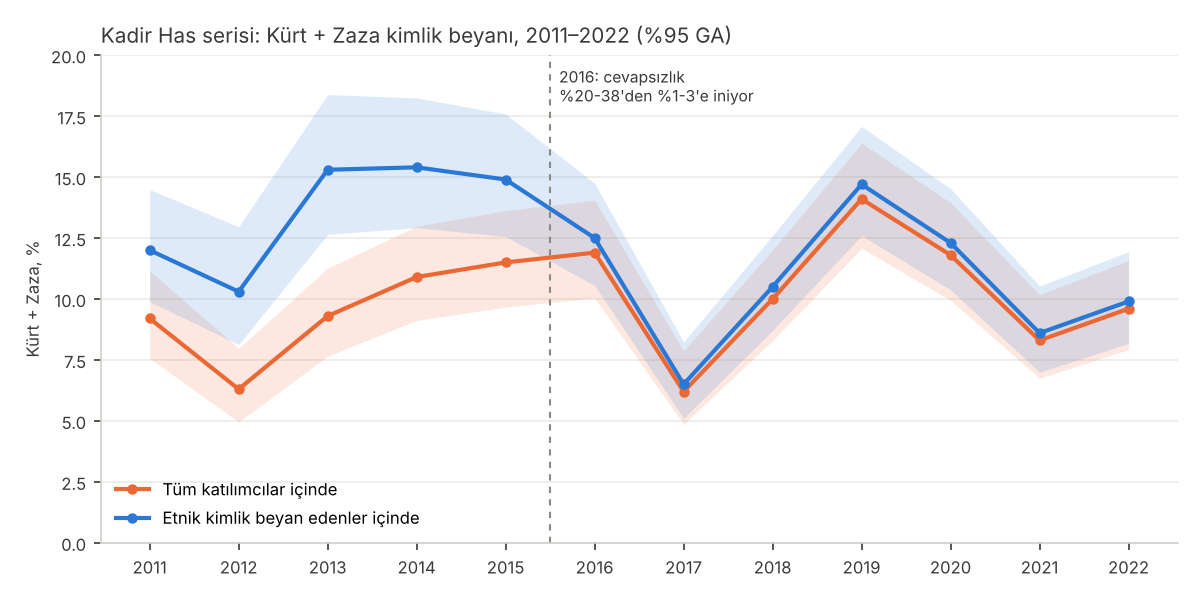

In [7]:
kh = df[df.institution=='Kadir Has Üniversitesi'].copy()
kh['n_decl'] = kh.n * (kh.turk_pct + kh.pct) / 100
rows = [pool(kh, label='KHAS — tüm katılımcılar'),
        pool(kh, 'pct_declarers', 'n_decl', label='KHAS — beyan edenler içinde'),
        pool(kh[kh.field_year<=2015], 'pct_declarers', 'n_decl', label='KHAS 2011–2015 (beyan edenler)'),
        pool(kh[kh.field_year>=2016], 'pct_declarers', 'n_decl', label='KHAS 2016–2022 (beyan edenler)')]
display(pd.DataFrame(rows).drop(columns=['mu_logit','se_logit']))
kh['year_c'] = kh.field_year - 2016
display(meta_regression(kh.assign(n=kh.n_decl, pct=kh.pct_declarers), ['year_c']))
khas_trend(kh, '../outputs/figures/khas_trend.png'); Image('../outputs/figures/khas_trend.png')

In [8]:
# Türk beyanı ile Kürt+Zaza beyanı ve cevapsızlık arasındaki ilişki (yıllar eşleştirilmiş)
from scipy import stats
nonresp = 100 - kh.turk_pct - kh.pct
out = []
for lab, a, b in [('Türk ↔ Kürt+Zaza', kh.turk_pct, kh.pct), ('Türk ↔ cevapsızlık', kh.turk_pct, nonresp)]:
    r, p = stats.pearsonr(a, b); zf = np.arctanh(r); s = 1/np.sqrt(len(a)-3)
    out.append(dict(iliski=lab, r=r, ga_alt=np.tanh(zf-1.96*s), ga_ust=np.tanh(zf+1.96*s), p=p))
pd.DataFrame(out)

,iliski,r,ga_alt,ga_ust,p
0,Türk ↔ Kürt+Zaza,0.13,-0.48,0.65,0.69
1,Türk ↔ cevapsızlık,-0.99,-1.00,-0.96,0.00


## 5. AREA 2025: 'Türkiyeli' tercihi, etnik köken temelli tahminle kıyaslama
'Türkiyeli' tercih edenleri Türk ulusal kimliğine muhalif bir grup olarak ele alıyoruz. Bu payın, son dönem (2018 ve sonrası) etnik köken sorularından elde edilen Kürt/Zaza havuzuyla karşılaştırılması, 'Türkiyeli' tercihinin etnik Kürt beyanının ötesine geçip geçmediğini gösterir.

In [9]:
recent = eth[eth.field_year>=2018]
r_recent = pool(recent, label='Etnik köken, 2018–2022 havuzu')
area = df[df.study_id=='AREA2025'].iloc[0]
lo, hi = wilson_ci([area.pct], [area.n])
diff = area.pct - r_recent['pooled_pct']
se_area = np.sqrt(area.pct/100*(1-area.pct/100)/area.n)*100
se_pool = (r_recent['ci_high']-r_recent['ci_low'])/(2*1.96)
zt = diff/np.sqrt(se_area**2+se_pool**2); p = 2*(1-stats.norm.cdf(abs(zt)))
pd.DataFrame([dict(karsilastirma='AREA 2025 Türkiyeli − etnik Kürt/Zaza havuzu (2018–22)',
                   area_pct=area.pct, area_ga=f'{lo[0]:.1f}–{hi[0]:.1f}',
                   havuz_pct=r_recent['pooled_pct'], havuz_ga=f"{r_recent['ci_low']:.1f}–{r_recent['ci_high']:.1f}",
                   fark_puan=diff, z=zt, p=p)])

,karsilastirma,area_pct,area_ga,havuz_pct,havuz_ga,fark_puan,z,p
0,AREA 2025 Türkiyeli − etnik Kürt/Zaza havuzu (...,18.20,16.6–20.0,12.44,10.0–15.3,5.76,3.61,0.00


## 6. Duyarlılık analizleri

In [10]:
sens = [main,
        pool(df[df.n_assumed==0], label='n varsayılan KONDA 2011/2021 hariç'),
        pool(df[df.study_id!='KONDA2006'], label='KONDA 2006 (geniş tanım) hariç'),
        pool(df[df.measure_type=='etnik köken'], label='Yalnızca etnik köken sorusu'),
        pool(df[df.institution!='Kadir Has Üniversitesi'], label='Kadir Has hariç (k=6)')]
display(pd.DataFrame(sens).drop(columns=['mu_logit','se_logit']))
leave_one_out(df)

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,Tüm çalışmalar (k=18),18,11.45,10.23,12.79,6.87,18.47,338.78,0.00,94.98,0.07
1,n varsayılan KONDA 2011/2021 hariç,16,10.84,9.62,12.19,6.48,17.59,264.64,0.00,94.33,0.06
2,KONDA 2006 (geniş tanım) hariç,17,11.25,9.65,13.06,5.59,21.33,337.73,0.00,95.26,0.12
3,Yalnızca etnik köken sorusu,16,11.22,9.99,12.59,6.79,17.99,272.99,0.00,94.51,0.06
4,Kadir Has hariç (k=6),6,14.95,12.88,17.29,8.53,24.89,151.03,0.00,96.69,0.04


,omitted,pooled_pct,ci_low,ci_high,I2
0,KHAS2011,11.59,10.34,12.97,95.05
1,KHAS2012,11.82,10.60,13.16,94.61
2,KHAS2013,11.58,10.33,12.96,95.06
3,KHAS2014,11.48,10.22,12.87,95.20
4,KHAS2015,11.44,10.18,12.83,95.23
5,KHAS2016,11.42,10.16,12.81,95.25
6,KHAS2017,11.83,10.61,13.16,94.60
7,KHAS2018,11.54,10.28,12.92,95.13
8,KHAS2019,11.30,10.04,12.69,95.27
9,KHAS2020,11.42,10.16,12.82,95.24


## 7. Küçük çalışma etkisi (Egger) ve huni grafiği
Not: Bunlar yayımlanmış hakemli makaleler değil, kurumların düzenli kamuoyu araştırmaları. Egger testi burada yayın yanlılığından çok, büyük ve küçük örneklemli araştırmaların sistematik olarak farklı sonuç verip vermediğine dair bir tanı aracı olarak okunmalı.

,intercept,se,t,df,p
0,-2.62,1.42,-1.84,16,0.08


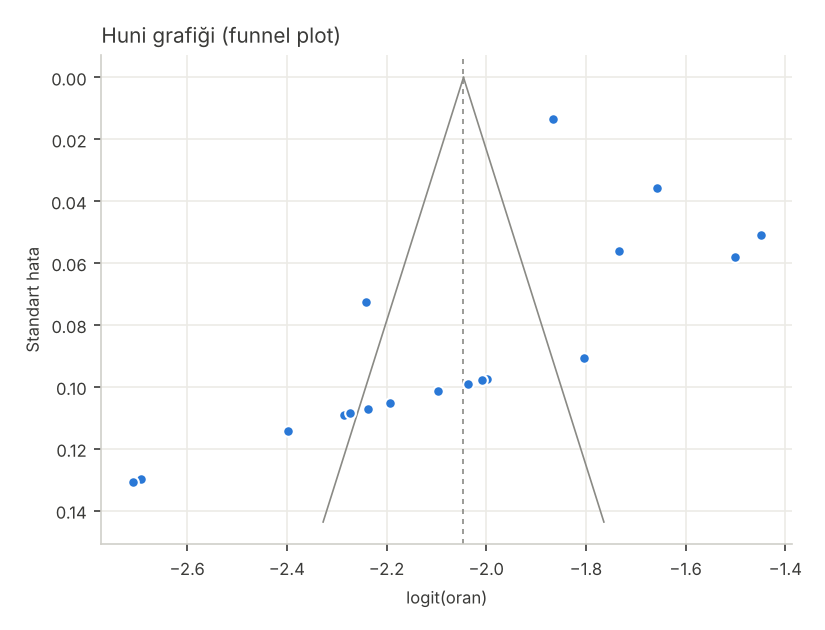

In [11]:
funnel(df, '../outputs/figures/funnel.png')
display(pd.DataFrame([egger_test(df)])); Image('../outputs/figures/funnel.png')

## 8. Ek analiz: Alevi kimliği beyanı

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,Alevi beyanı (k=6),6,4.68,4.09,5.36,3.17,6.86,10.98,0.05,54.46,0.02


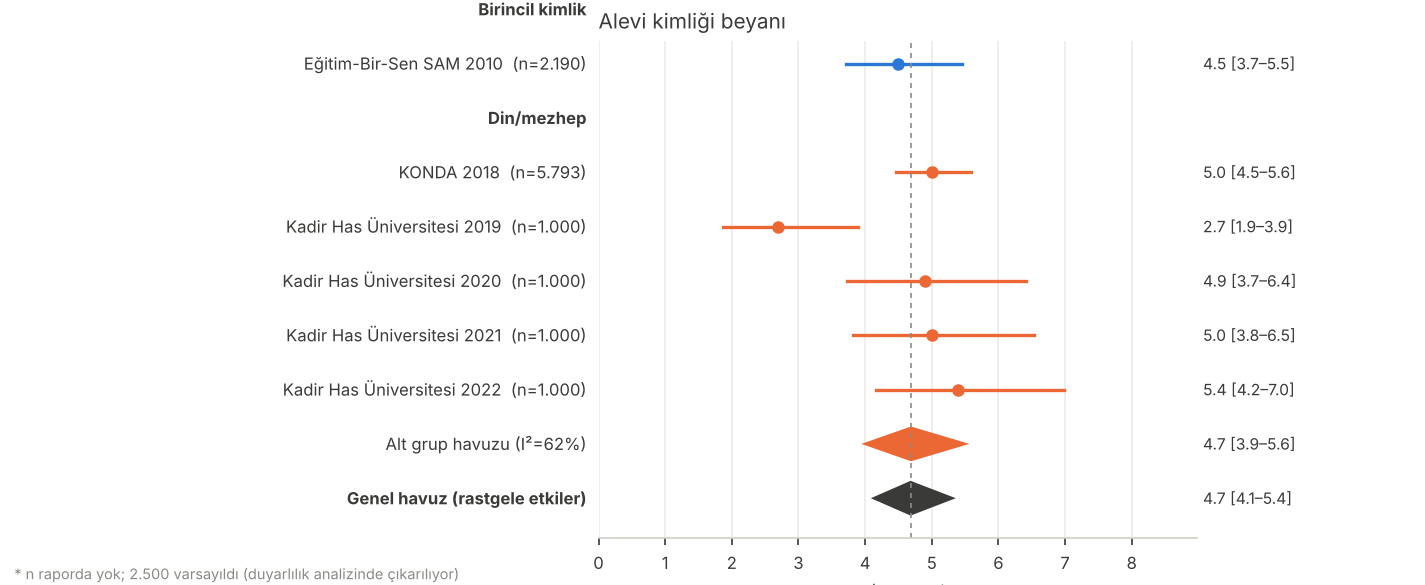

In [12]:
al = pool(alevi, label='Alevi beyanı (k=6)')
display(pd.DataFrame([al]).drop(columns=['mu_logit','se_logit']))
forest(alevi.assign(n_assumed=0), 'measure_type', '../outputs/figures/forest_alevi.png', 'Alevi kimliği beyanı')
Image('../outputs/figures/forest_alevi.png')

## 9. Ek analiz: Türk kimliği beyanı (ölçüm türüne göre)

In [13]:
tk = df.dropna(subset=['turk_pct']).assign(pct=lambda d: d.turk_pct)
sg_tk, test_tk = subgroup_test(tk, 'measure_type')
display(sg_tk.drop(columns=['mu_logit','se_logit'])); test_tk

,analysis,k,pooled_pct,ci_low,ci_high,pi_low,pi_high,Q,p_Q,I2,tau2
0,measure_type = etnik köken,15,77.50,71.92,82.24,48.54,92.64,1170.33,0.00,98.80,0.34
1,measure_type = birincil kimlik,1,52.60,50.50,54.68,NaN,NaN,0.00,NaN,0.00,0.00
2,measure_type = ulusal ad tercihi,1,79.59,77.76,81.29,NaN,NaN,0.00,NaN,0.00,0.00


{'Q_between': np.float64(340.170825402313), 'df': 2, 'p': np.float64(0.0)}

In [14]:
# Tabloları dışa aktar
with pd.ExcelWriter('../outputs/tables/meta_analysis_results.xlsx') as w:
    df.to_excel(w, sheet_name='coding_table', index=False)
    pd.DataFrame([main]).to_excel(w, sheet_name='overall', index=False)
    sg_measure.to_excel(w, sheet_name='subgroup_measure', index=False)
    sg_inst.to_excel(w, sheet_name='subgroup_institution', index=False)
    meta_regression(eth, ['year_c']).to_excel(w, sheet_name='metareg_year', index=False)
    pd.DataFrame(rows).to_excel(w, sheet_name='khas', index=False)
    pd.DataFrame(sens).to_excel(w, sheet_name='sensitivity', index=False)
    leave_one_out(df).to_excel(w, sheet_name='leave_one_out', index=False)
    pd.DataFrame([al]).to_excel(w, sheet_name='alevi', index=False)
    sg_tk.to_excel(w, sheet_name='turk_identity', index=False)
print('ok')

ok
